In [1]:
import numpy as np
import pandas as pd
import ast

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
import seaborn as sns

# Loading Data

In [2]:
df = pd.read_pickle("data/df_train.pkl")

df_train, df_val = train_test_split(df, test_size= 0.1, random_state=42)

In [3]:
X_train = df_train.business_description_embedding.apply(ast.literal_eval).tolist()
X_train = np.array(X_train)

X_val = df_val.business_description_embedding.apply(ast.literal_eval).tolist()
X_val = np.array(X_val)

In [4]:
df_train.head(3)

,id,industry,business_description_embedding
31138,34170,Financial Services,"[0.019633012,0.009427597,0.006240986,0.0177257..."
15120,16504,Technology Hardware & Equipment,"[0.026561439,-0.049749356,-0.006847293,-0.0088..."
23693,25893,Consumer Durables & Apparel,"[0.0115894,-0.035240766,-0.029952582,0.0226988..."


In [5]:
X_train.shape

(28535, 768)

# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set

#

In [6]:
set_train = set(df_train["industry"])
set_val = set(df_val["industry"])

is_subset = set_val.issubset(set_train)
    
print(f"All classes in training set are in the validation set: {is_subset}")

num_cls = len(set_train)

print(f"The total number of classes is: {num_cls}")

All classes in training set are in the validation set: True
The total number of classes is: 25


The boolean check returns True so all classes from the training set appear in the validation set 

In [7]:
encoder = LabelEncoder()
encoder.fit(df['industry'])

y_train = encoder.transform(df_train['industry'])
y_val =  encoder.transform(df_val['industry'])

In [8]:
label_map = {idx: label for idx, label in enumerate(encoder.classes_)}
label_map

{0: 'Automobiles & Components',
 1: 'Banks',
 2: 'Capital Goods',
 3: 'Commercial & Professional Services',
 4: 'Consumer Discretionary Distribution & Retail',
 5: 'Consumer Durables & Apparel',
 6: 'Consumer Services',
 7: 'Consumer Staples Distribution & Retail',
 8: 'Energy',
 9: 'Equity Real Estate Investment Trusts (REITs)',
 10: 'Financial Services',
 11: 'Food, Beverage & Tobacco',
 12: 'Health Care Equipment & Services',
 13: 'Household & Personal Products',
 14: 'Insurance',
 15: 'Materials',
 16: 'Media & Entertainment',
 17: 'Pharmaceuticals, Biotechnology & Life Sciences',
 18: 'Real Estate Management & Development',
 19: 'Semiconductors & Semiconductor Equipment',
 20: 'Software & Services',
 21: 'Technology Hardware & Equipment',
 22: 'Telecommunication Services',
 23: 'Transportation',
 24: 'Utilities'}

# Visualize the data

### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)

### Class distribution

In [9]:
# Plot the class distribution or provide a table that shows how many times each class (industry) appears
# Describe your findings
industry_counts = (
    df['industry']
    .value_counts()
    .reset_index()
)
industry_counts.columns = ['industry','number_of_companies']

print(industry_counts)

                                          industry  number_of_companies
0                                        Materials                 8394
1                                    Capital Goods                 3127
2                               Financial Services                 1936
3   Pharmaceuticals, Biotechnology & Life Sciences                 1925
4                  Technology Hardware & Equipment                 1547
5                              Software & Services                 1537
6                                           Energy                 1326
7                      Consumer Durables & Apparel                 1164
8                         Food, Beverage & Tobacco                 1094
9                 Health Care Equipment & Services                 1014
10                                           Banks                  948
11                           Media & Entertainment                  915
12            Real Estate Management & Development              

C:\Users\fraia\AppData\Local\Temp\ipykernel_6560\948573579.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=industry_counts, x="number_of_companies", y="industry", palette="husl")


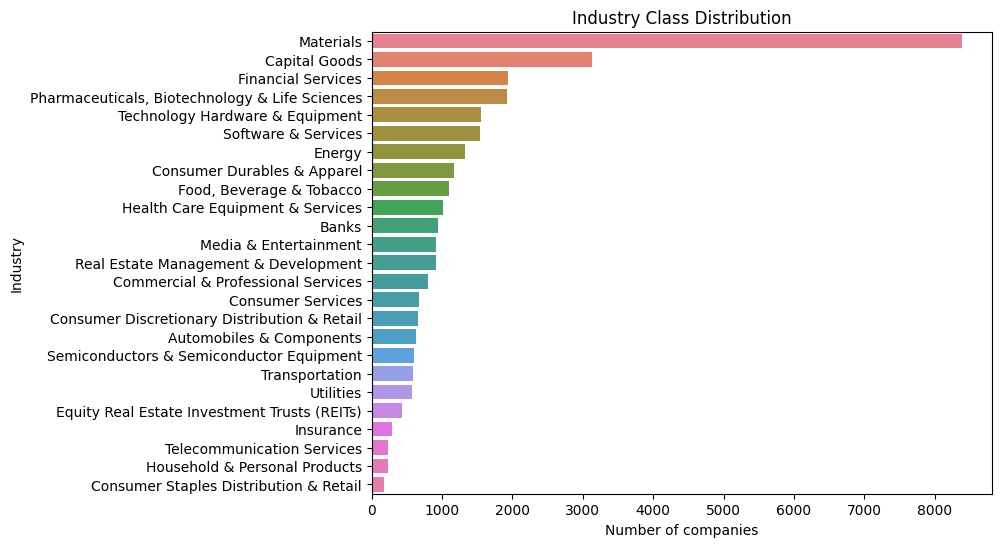

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.barplot(data=industry_counts, x="number_of_companies", y="industry", palette="husl")

plt.title('Industry Class Distribution')
plt.ylabel('Industry')
plt.xlabel('Number of companies')
plt.show()

### PCA - Dimensionality reduction and visualization

Number of principal components: (28535, 224)


Text(0, 0.5, 'Principal Component 2')

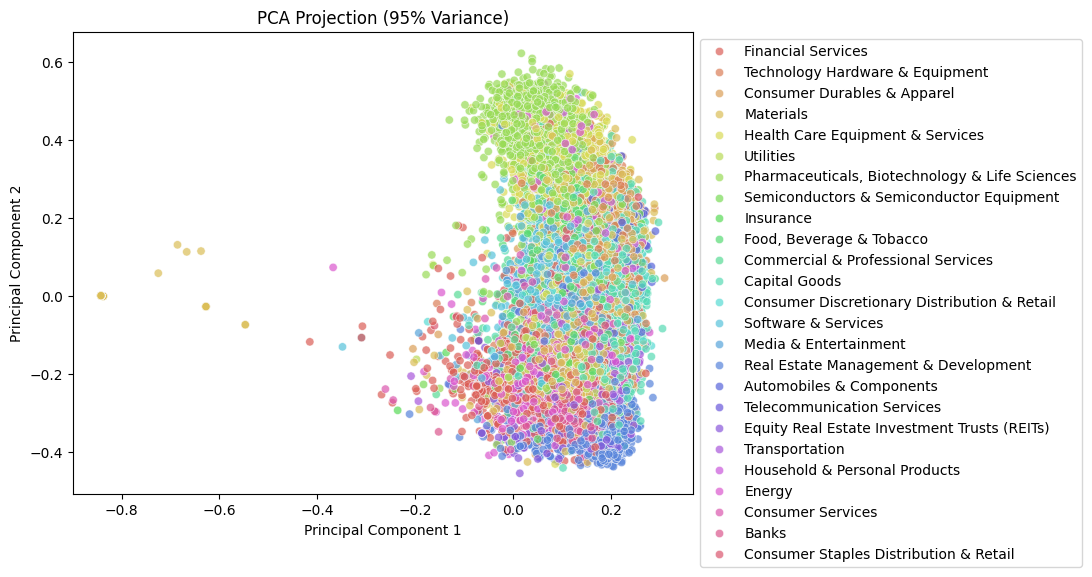

In [11]:
# Perform a PCA and plot the projected data. Color the scatter plot based on the classes
# Analyse what you see

from sklearn.preprocessing import StandardScaler

pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)
print(f"Number of principal components: {X_reduced.shape}")

pca_df = pd.DataFrame(X_reduced, columns=[f"PC{i+1}" for i in range(X_reduced.shape[1])])
pca_df['industry'] = encoder.inverse_transform(y_train)

# Plot
plt.figure(figsize=(8, 6))
sc = sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='industry',
    data= pca_df,
    palette='hls',
    alpha=0.7
)
sc.legend(bbox_to_anchor= (1,1))
plt.title('PCA Projection (95% Variance)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

### Interpretation

**PCA projection.**
The plot above shows the PCA projection of the embeddings. The first **224 components** (out of the original **768 dimensions**) capture **95% of the variance** in the data.

**Overlapping clusters.**
Companies from the same industry form several visible clusters. However, these clusters **overlap strongly**, which shows that the features are very similar across industries.

**Industries with a strong signal.**
Some industries, such as *Pharmaceuticals, Biotechnology & Life Sciences*, stand out clearly. This should make them easier to classify correctly.

**Implication.**
Overall, the heavy overlap suggests that classifying industries correctly will not be an easy task.


# Fitting and comparing Classifier Models

### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots! 

In [12]:
# your code
# Logistic Regression
log_reg = LogisticRegression()
log_reg_1 = log_reg.fit(X_reduced, y_train)

In [13]:
#Knn Classifier
knn_clf = KNeighborsClassifier()
knn_clf_1 = knn_clf.fit(X_reduced, y_train)

In [14]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, classification_report

#PCA reduction validation set
X_val_reduced = pca.transform(X_val)
y_pred_lg = log_reg_1.predict(X_val_reduced)
y_pred_knn = knn_clf_1.predict(X_val_reduced)
y_true = y_val

print("\nLogistic Regression")
precision_lg = precision_score(y_true, y_pred_lg, average="weighted")
recall_lg = recall_score(y_true, y_pred_lg, average="weighted")
f1_lg = f1_score(y_true, y_pred_lg, average="weighted")
accuracy_lg = accuracy_score(y_true, y_pred_lg)

print(f"Precision: {precision_lg:.3f}")
print(f"Recall:    {recall_lg:.3f}")
print(f"F1 Score:  {f1_lg:.3f}")
print(f"Accuracy: {accuracy_lg:.3f}")

print("\nKnn Classifier")
precision_knn = precision_score(y_true, y_pred_knn, average="weighted")
recall_knn = recall_score(y_true, y_pred_knn, average="weighted")
f1_knn = f1_score(y_true, y_pred_knn, average="weighted")
accuracy_knn = accuracy_score(y_true, y_pred_knn)

print(f"Precision: {precision_knn:.3f}")
print(f"Recall:    {recall_knn:.3f}")
print(f"F1 Score:  {f1_knn:.3f}")
print(f"Accuracy: {accuracy_knn:.3f}")


Logistic Regression
Precision: 0.766
Recall:    0.770
F1 Score:  0.764
Accuracy: 0.770

Knn Classifier
Precision: 0.751
Recall:    0.753
F1 Score:  0.749
Accuracy: 0.753


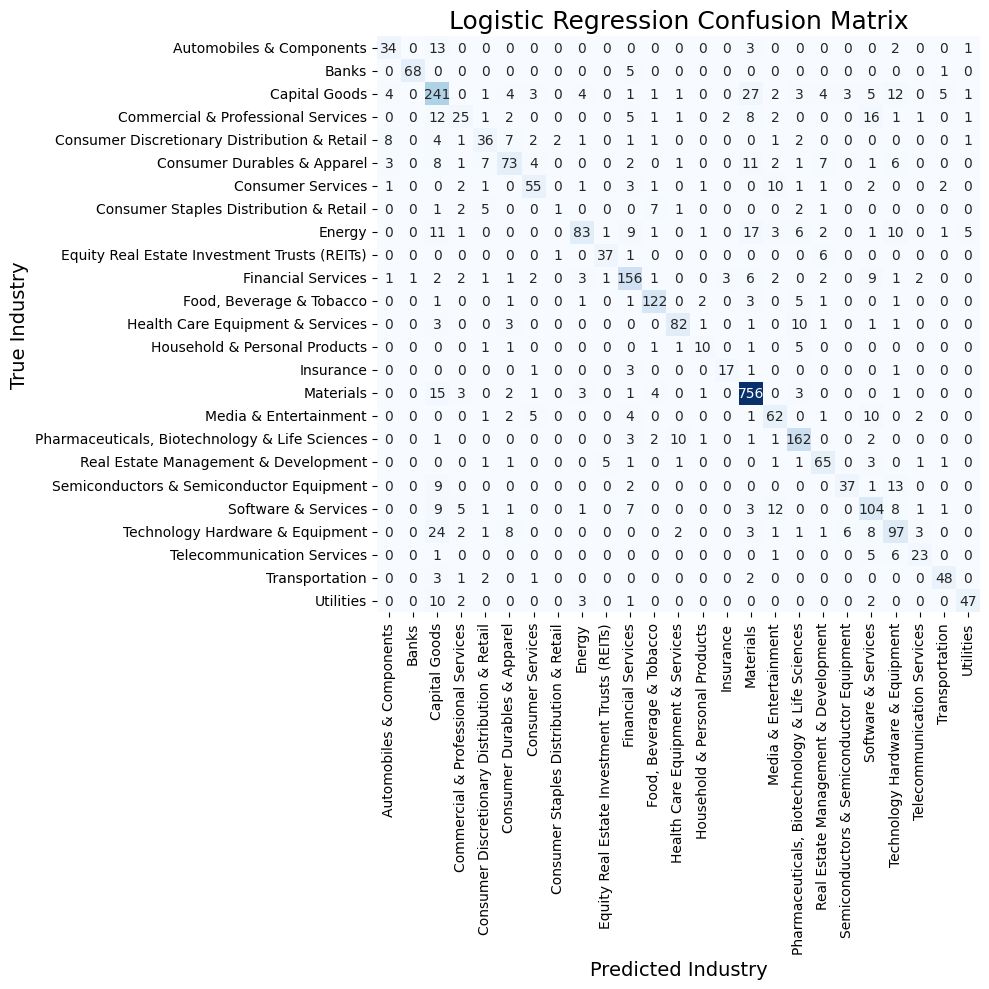

In [15]:
target_names = encoder.classes_

cm1 = confusion_matrix(y_true, y_pred_lg)
cm2 = confusion_matrix(y_true, y_pred_knn)

plt.figure(figsize=(10, 10))

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', cbar=False, yticklabels=target_names, xticklabels=target_names)
plt.title('Logistic Regression Confusion Matrix', fontsize=18)
plt.xlabel('Predicted Industry', fontsize=14)
plt.ylabel('True Industry', fontsize=14)

plt.tight_layout()
plt.show()

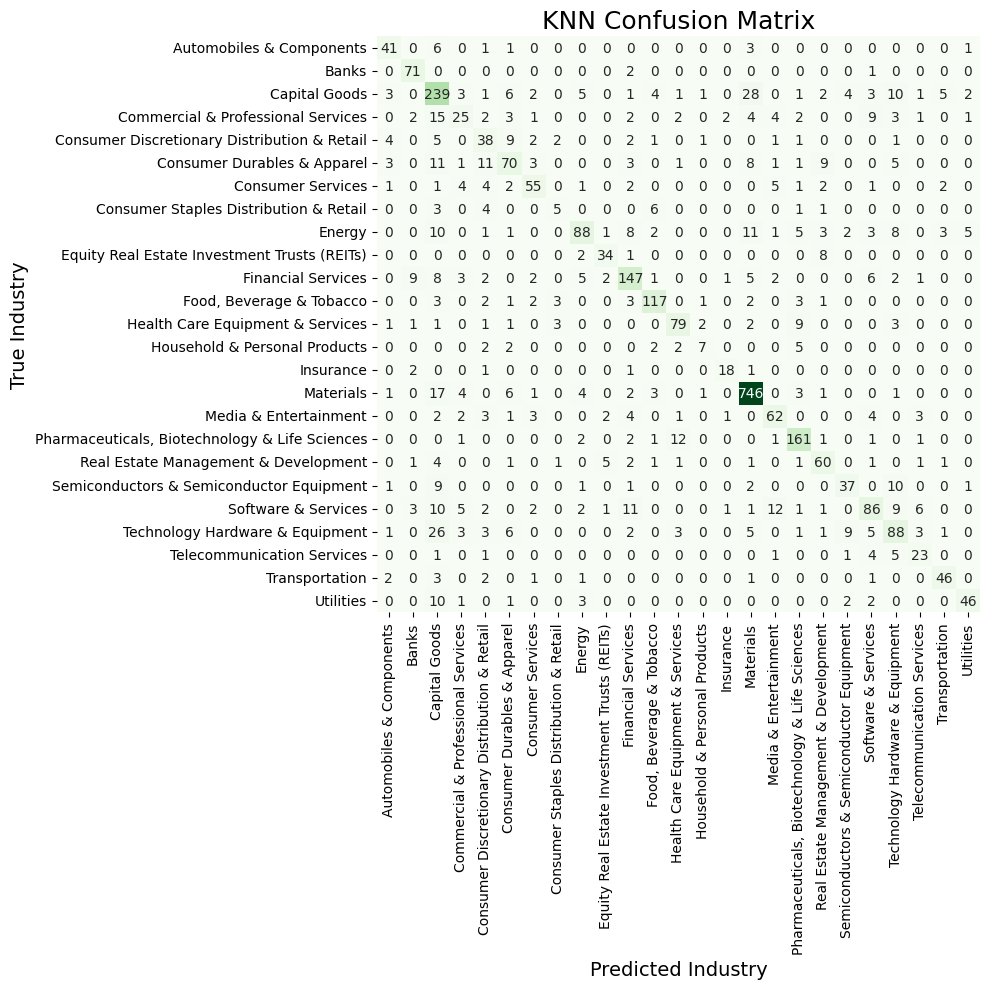

In [16]:
plt.figure(figsize=(10, 10))

sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', cbar=False, yticklabels=target_names, xticklabels = target_names)
plt.title('KNN Confusion Matrix', fontsize=18)
plt.xlabel('Predicted Industry', fontsize=14)
plt.ylabel('True Industry', fontsize=14)

plt.tight_layout()
plt.show()

## Conclusions
### Score Interpretation

**Accuracy** measures the proportion of samples that were classified correctly out of all predictions.
The **F1 Score** is the harmonic mean of precision and recall, ensuring a balance between the two measures. Compared to accuracy, the F1 Score is a better indicator of how the model handles misclassified cases.

Considering the high dimensionality of the data and the fact that we only have one input variable (the embeddings of the business description), the model classifies fairly well.

### Analysis of Classification Errors

**Class representation.**
The errors partially correlate with how well each class is represented. Larger classes, despite having moderate F1 scores, contribute the most to the total accuracy: they appear more frequently and are therefore correctly predicted more often.

**Related industries get confused.**
Some related industries share lower scores, which suggests their descriptions are similar and get mixed up during classification. For example:

- **Technology:** Semiconductors, Software, Tech Hardware, and Telecommunication Services
- **Consumer:** Consumer Discretionary Distribution & Retail, Consumer Durables & Apparel, Consumer Staples Distribution & Retail, and Household & Personal Products

**Distinctive industries score higher.**
*Transportation* and *Pharmaceuticals, Biotechnology & Life Sciences* likely have more technical, highly specific descriptions. This makes them more distinctive within the dataset and leads to higher scores.

**Model comparison.**
Both models misclassify in similar ways: well-represented classes are classified better than underrepresented ones. However, their misclassifications are not identical, so an **ensemble of the two classifiers** could potentially improve predictions.


# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of an industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- Designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

## Scoring

Your submission is scored with the function `confidence_score` below:

$$\text{score} = F_1^{\text{weighted}}(y, \hat{y}_{pred}) \cdot \left(1 - \text{Brier}\right), \qquad \text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \left(\hat{y}_{confidence}[i] - \mathbb{1}[\hat{y}_{pred}[i] = y_i]\right)^2$$

- **Weighted F1** measures how good your predicted industries are (the confidence does not enter here).
- **Brier score** measures how good your confidence is: $\hat{y}_{confidence}[i]$ should be the probability that prediction $i$ is correct.
- The Brier term is smallest when your confidence is *calibrated*: among all predictions with confidence 0.8, about 80% should be correct.
- Always reporting confidence 1.0 does not pay off (every wrong prediction costs the maximum penalty), and neither does reporting very low confidence everywhere.

In [17]:
import numpy as np
import pandas as pd
import ast

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
import seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

In [18]:
df_company_industry = pd.read_pickle("data/df_train.pkl")
df_company_financials =  pd.read_pickle("data/df_financials_train.pkl")

Text(0.5, 1.0, 'Asset Turnover (Revenue / Total Assets)')

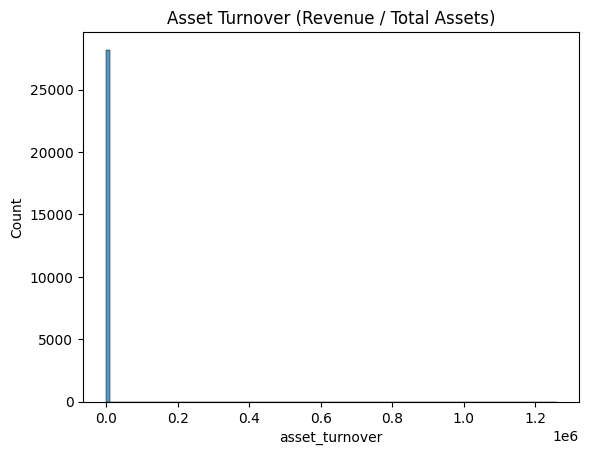

In [19]:
# merge data and clean

df = df_company_industry.merge(df_company_financials, on="id")

sns.histplot(df.asset_turnover, bins=100)
plt.title("Asset Turnover (Revenue / Total Assets)")

In [20]:
percentile_95 = df["asset_turnover"].quantile(0.95)

print("95s Percentile: ", percentile_95)
df = df[df.asset_turnover < percentile_95]
df = df[df.asset_turnover > 0]

df.shape

95s Percentile:  1.8018310430448619


(24602, 7)

Text(0.5, 0, 'Asset Turnover')

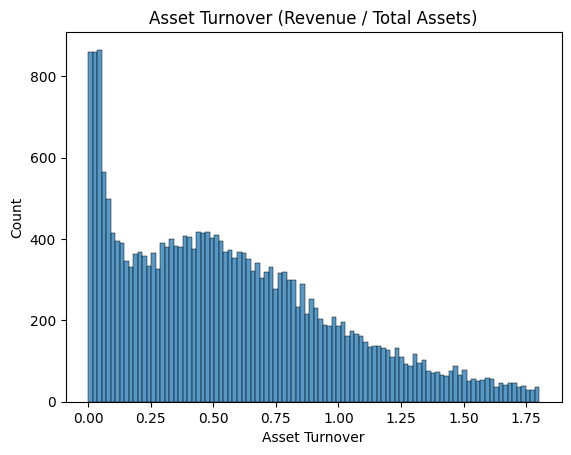

In [21]:
sns.histplot(df.asset_turnover, bins=100)
plt.title("Asset Turnover (Revenue / Total Assets)")
plt.xlabel("Asset Turnover")

Text(0.5, 1.0, 'Net Profit Margins')

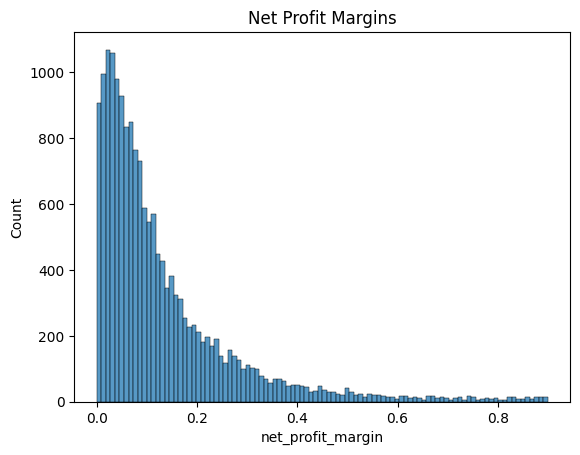

In [22]:
df_margins = df_company_industry.merge(df_company_financials, on="id")
df_margins = df_margins[df_margins.net_profit_margin < 0.9]
df_margins = df_margins[(~df_margins.net_profit_margin.isna()) & (df_margins.net_profit_margin >= 0)]
sns.histplot(df_margins.net_profit_margin, bins=100)
plt.title("Net Profit Margins")

In [23]:
df_margins.shape

(17316, 7)

Text(0.5, 1.0, 'Distribution of log-profit margins')

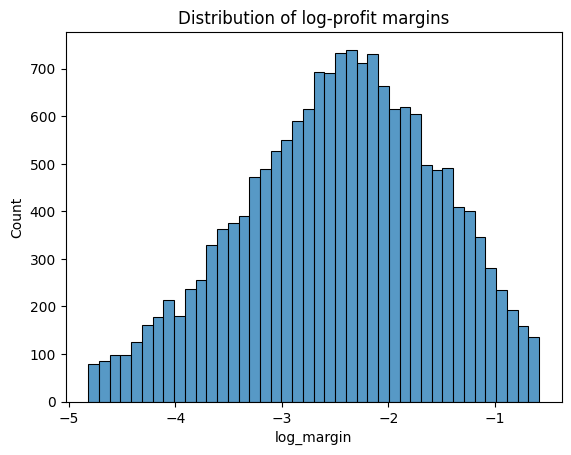

In [24]:
# handling outliers
df_margins = df_margins[(df_margins.net_profit_margin > 0) & (df_margins.net_profit_margin< 0.55)]
SHIFT =  0.008
df_margins["log_margin"] = np.log(df_margins["net_profit_margin"].values + SHIFT)
sns.histplot(df_margins.log_margin)
plt.title("Distribution of log-profit margins")

In [25]:
df_ind_stats = df.groupby("industry")["asset_turnover"].agg(["count", "mean", "std"], ).reset_index()
df_ind_stats = df_ind_stats[~df_ind_stats["std"].isna()]
df_ind_stats.to_csv("industry_rev_per_asset.csv")
df_ind_stats

,industry,count,mean,std
0,Automobiles & Components,549,0.806277,0.394972
1,Banks,866,0.050086,0.087624
2,Capital Goods,2696,0.657397,0.376228
3,Commercial & Professional Services,540,0.673462,0.441495
4,Consumer Discretionary Distribution & Retail,448,0.886146,0.468639
5,Consumer Durables & Apparel,982,0.754376,0.404543
6,Consumer Services,534,0.614537,0.422443
7,Consumer Staples Distribution & Retail,88,1.057864,0.479604
8,Energy,917,0.523974,0.406180
9,Equity Real Estate Investment Trusts (REITs),392,0.110329,0.098930


In [26]:
# Assuming your data is already loaded as df with columns: industry, margin
# First, compute industry statistics
df_ind_stats = df.groupby("industry")["asset_turnover"].agg(["count", "mean", "std"]).reset_index()
df_ind_stats = df_ind_stats[~df_ind_stats["std"].isna()]

# Display summary statistics
print(f"Total number of industries: {len(df_ind_stats)}")
print(f"Total number of companies: {df_ind_stats['count'].sum():.0f}")
print(f"\nIndustry Statistics Sample:")
print(df_ind_stats.head(10).to_string(index=False))

# Find industries with most extreme margins
print("\n📈 Industries with HIGHEST Asset Turnover:")
print(df_ind_stats.nlargest(5, 'mean')[['industry', 'mean', 'std']].to_string(index=False))

print("\n📉 Industries with LOWEST Asset Turnover:")
print(df_ind_stats.nsmallest(5, 'mean')[['industry', 'mean', 'std']].to_string(index=False))

Total number of industries: 25
Total number of companies: 24602

Industry Statistics Sample:
                                    industry  count     mean      std
                    Automobiles & Components    549 0.806277 0.394972
                                       Banks    866 0.050086 0.087624
                               Capital Goods   2696 0.657397 0.376228
          Commercial & Professional Services    540 0.673462 0.441495
Consumer Discretionary Distribution & Retail    448 0.886146 0.468639
                 Consumer Durables & Apparel    982 0.754376 0.404543
                           Consumer Services    534 0.614537 0.422443
      Consumer Staples Distribution & Retail     88 1.057864 0.479604
                                      Energy    917 0.523974 0.406180
Equity Real Estate Investment Trusts (REITs)    392 0.110329 0.098930

📈 Industries with HIGHEST Asset Turnover:
                                    industry     mean      std
      Consumer Staples Distribu

In [27]:
from sklearn.metrics import roc_auc_score
d = df.dropna(subset=["asset_turnover"])
aucs = {i: roc_auc_score(d["industry"] == i, d["asset_turnover"]) for i in d["industry"].unique()}
print(pd.Series(aucs).sort_values())

Banks                                             0.068514
Equity Real Estate Investment Trusts (REITs)      0.152104
Financial Services                                0.220482
Real Estate Management & Development              0.230664
Insurance                                         0.323782
Utilities                                         0.358776
Pharmaceuticals, Biotechnology & Life Sciences    0.398406
Telecommunication Services                        0.469391
Energy                                            0.470855
Semiconductors & Semiconductor Equipment          0.502239
Transportation                                    0.509339
Media & Entertainment                             0.530739
Health Care Equipment & Services                  0.533342
Consumer Services                                 0.537786
Materials                                         0.559369
Software & Services                               0.564094
Commercial & Professional Services                0.5754

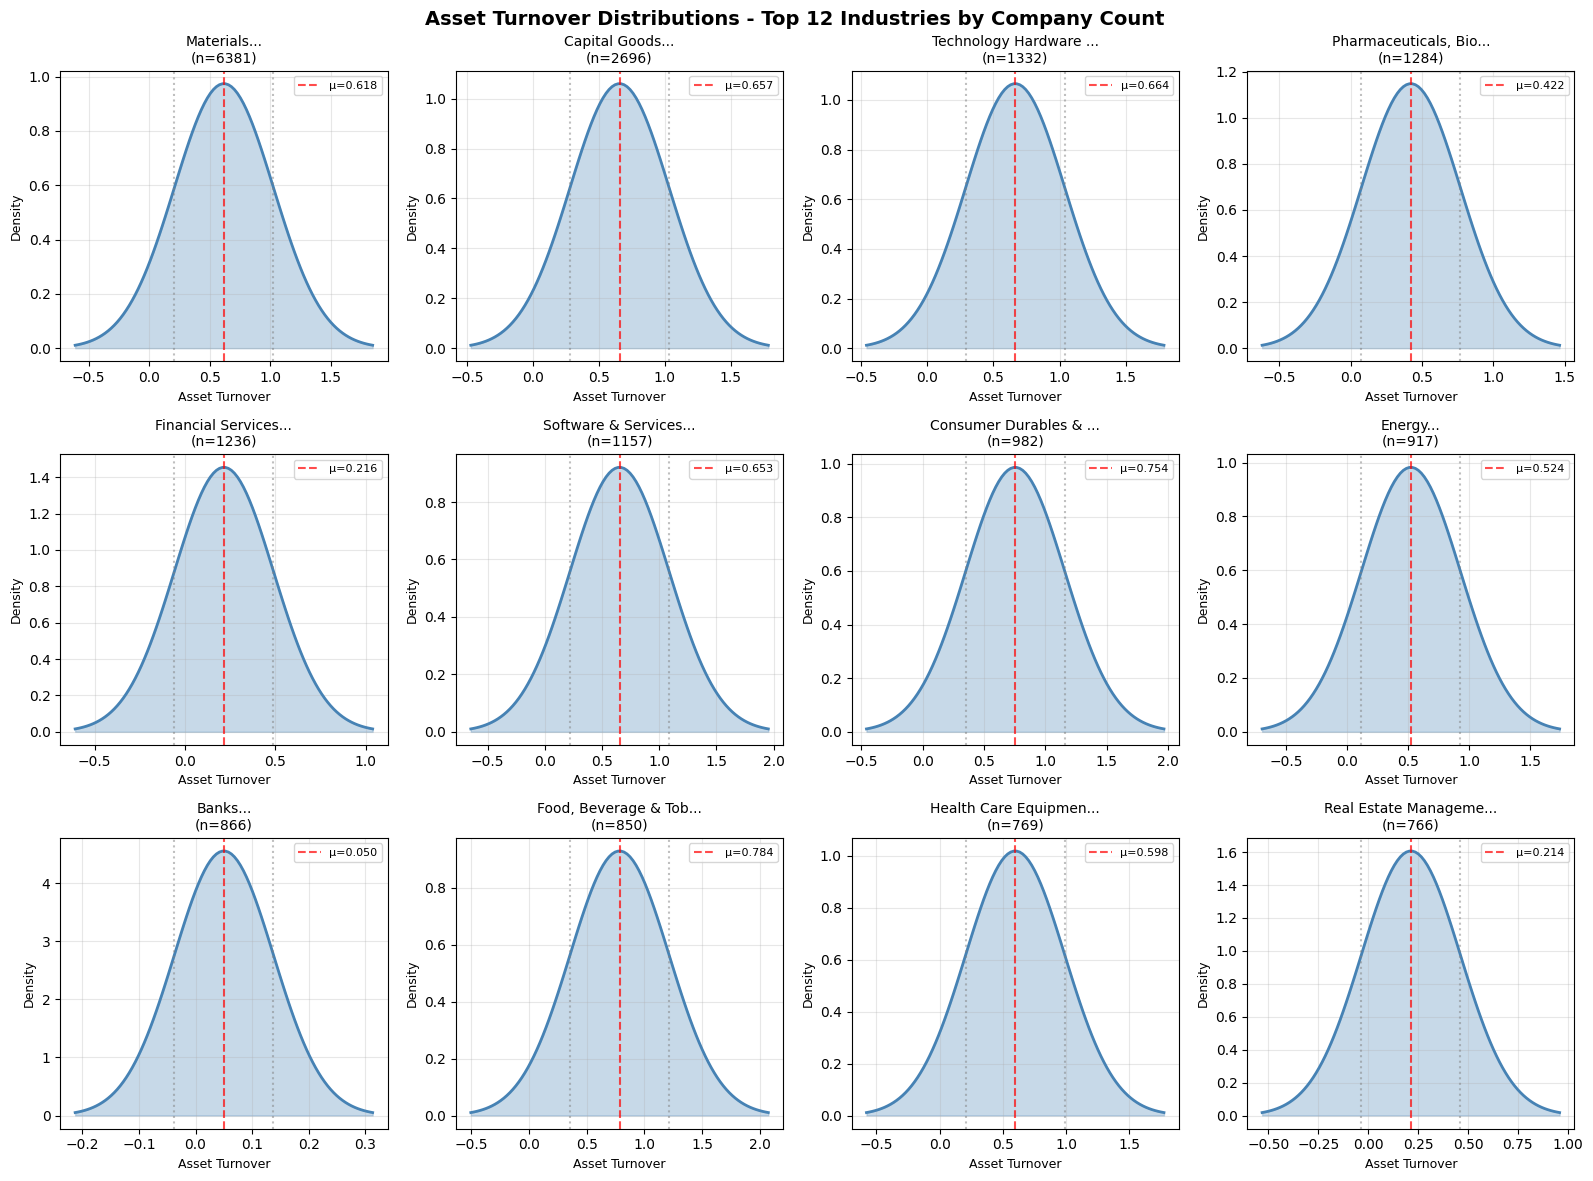

In [28]:
# Select top industries by company count for visualization
top_industries = df_ind_stats.nlargest(12, 'count')

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, (_, row) in enumerate(top_industries.iterrows()):
    ax = axes[idx]
    
    # Generate theoretical distribution based on stats
    x = np.linspace(row['mean'] - 3*row['std'], row['mean'] + 3*row['std'], 100)
    y = stats.norm.pdf(x, row['mean'], row['std'])
    
    ax.plot(x, y, linewidth=2, color='steelblue')
    ax.fill_between(x, y, alpha=0.3, color='steelblue')
    
    # Add vertical lines for mean and ±1 std
    ax.axvline(row['mean'], color='red', linestyle='--', alpha=0.7, label=f"μ={row['mean']:.3f}")
    ax.axvline(row['mean'] - row['std'], color='gray', linestyle=':', alpha=0.5)
    ax.axvline(row['mean'] + row['std'], color='gray', linestyle=':', alpha=0.5)
    
    ax.set_title(f"{row['industry'][:20]}...\n(n={row['count']:.0f})", fontsize=10)
    ax.set_xlabel('Asset Turnover', fontsize=9)
    ax.set_ylabel('Density', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Asset Turnover Distributions - Top 12 Industries by Company Count', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

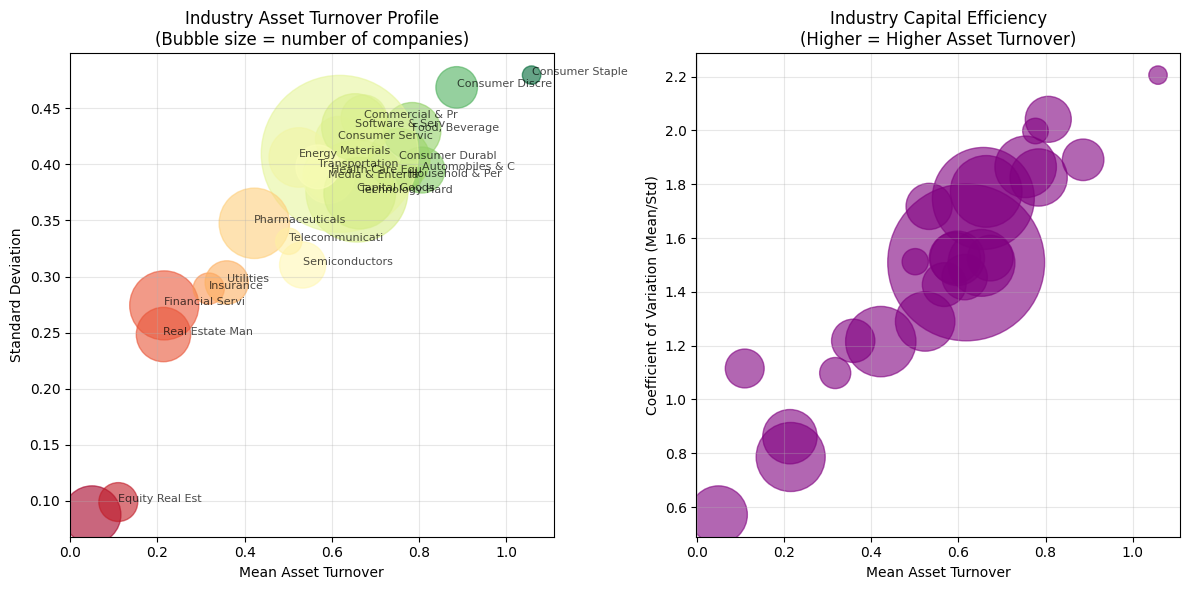

In [29]:
# Create a scatter plot of mean vs std to understand industry characteristics
plt.figure(figsize=(12, 6))

# Filter to industries with sufficient data
robust_industries = df_ind_stats[df_ind_stats['count'] >= 20]

plt.subplot(1, 2, 1)
scatter = plt.scatter(robust_industries['mean'], robust_industries['std'], 
                     s=robust_industries['count']*2, alpha=0.6, 
                     c=robust_industries['mean'], cmap='RdYlGn')
plt.xlabel('Mean Asset Turnover')
plt.ylabel('Standard Deviation')
plt.title('Industry Asset Turnover Profile\n(Bubble size = number of companies)')
#plt.colorbar(scatter, label='Mean Asset Turnover')
plt.grid(True, alpha=0.3)

# Add annotations for outlier industries
for _, row in robust_industries.iterrows():
    if row['std'] > robust_industries['std'].quantile(0.0) or row['mean'] > robust_industries['mean'].quantile(0.0):
        plt.annotate(row['industry'][:15], (row['mean'], row['std']), 
                    fontsize=8, alpha=0.7)

plt.subplot(1, 2, 2)
plt.scatter(robust_industries['mean'], robust_industries['mean']/robust_industries['std'],
           s=robust_industries['count']*2, alpha=0.6, color='purple')
plt.xlabel('Mean Asset Turnover')
plt.ylabel('Coefficient of Variation (Mean/Std)')
plt.title('Industry Capital Efficiency\n(Higher = Higher Asset Turnover)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
columns = ["id","industry","business_description_embedding", "asset_turnover", "country_code", "log_margin", "net_profit_margin"]
df = df_margins[columns]

In [31]:
df.isnull().sum()

id                                 0
industry                           0
business_description_embedding     0
asset_turnover                    74
country_code                       0
log_margin                         0
net_profit_margin                  0
dtype: int64

In [32]:
df_train_o, df_val_o = train_test_split(df, test_size= 0.1, random_state=42)

In [33]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [52]:
X_train_embed = df_train_o.business_description_embedding.apply(ast.literal_eval).tolist()
X_val_embed = df_val_o.business_description_embedding.apply(ast.literal_eval).tolist()
X_train_embed = np.array(X_train_embed)
X_val_embed = np.array(X_val_embed) #converts business embeddings into arrays

# PCA only on the embedding columns
pca_o = PCA(n_components=0.95)
X_train_embed_red = pca_o.fit_transform(X_train_embed)   # fit on train only
X_val_embed_red = pca_o.transform(X_val_embed)           # reuse the same projection

num_vars = ["log_margin", "net_profit_margin"]
X_train_num = df_train_o[num_vars].to_numpy()
X_val_num = df_val_o[num_vars].to_numpy()

#Putting it all together
X_train_o = np.concatenate([X_train_embed_red, X_train_num], axis=1)
X_val_o = np.concatenate([X_val_embed_red, X_val_num], axis=1)

print(X_train_o.shape, X_val_o.shape)

(15162, 203) (1685, 203)


In [53]:
le = LabelEncoder()
y_train_o = le.fit_transform(df_train_o['industry']) 
y_val_o =  le.transform(df_val_o['industry']) 

In [148]:
clf_lg = LogisticRegression(max_iter=20000, solver='lbfgs', class_weight='balanced')

param_grid = {
    'C': [3, 4, 5, 6, 7, 10]
}

grid_lg = GridSearchCV(
    estimator=clf_lg,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,  # Uses all CPU cores
    verbose=1
)

grid_lg.fit(X_train_o, y_train_o)

print("Best params (LG):", grid_lg.best_params_)
print("Best CV F1 (LG):", grid_lg.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best params (LG): {'C': 5}
Best CV F1 (LG): 0.7252768123273816


In [149]:
knn_clf_2 = KNeighborsClassifier()

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(
    knn_clf_2,
    param_grid_knn,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(X_train_o, y_train_o)

print("Best params (kNN):", grid_knn.best_params_)
print("Best CV F1 (kNN):", grid_knn.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params (kNN): {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
Best CV F1 (kNN): 0.7080361297578597


In [190]:
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Best models with the selected hyperparameters
clf_knn = KNeighborsClassifier(
    metric="manhattan", 
    n_neighbors=7,
    weights="distance"
)

clf_knn2 = KNeighborsClassifier(
    metric="cosine", 
    n_neighbors=9, 
    weights="distance")

clf_lr = LogisticRegression(
    C=10,
    max_iter=20000
)


# Soft voting ensemble
voting_clf = VotingClassifier(
    estimators=[
        ("clf_knn", clf_knn),
        ("clf_knn2", clf_knn2),
        ("clf_lr", clf_lr)
    ],
    voting="soft",
    weights=[1,1,2]
)

# Train
voting_clf.fit(X_train_o, y_train_o)

# Predict
y_pred = voting_clf.predict(X_val_o)
probabilities = voting_clf.predict_proba(X_val_o)

# Confidence = highest predicted class probability
confidences = np.max(probabilities, axis=1)

# Evaluation
precision = precision_score(
    y_val_o, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_val_o, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_val_o, y_pred, average="weighted", zero_division=0
)

results = (y_pred, confidences)

print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1:        {f1:.4f}")

Weighted Precision: 0.8241
Weighted Recall:    0.8196
Weighted F1:        0.8178


In [191]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_clf = CalibratedClassifierCV(voting_clf, method="isotonic", cv=5)
calibrated_clf.fit(X_train_o, y_train_o)

y_pred = calibrated_clf.predict(X_val_o)
probabilities = calibrated_clf.predict_proba(X_val_o)
confidences = np.max(probabilities, axis=1)

In [192]:
from sklearn.metrics import f1_score


def confidence_score(y_true, y_pred, confidence):
    """
    Score for the confidence weighted prediction task.

    Parameters:
    -----------
    y_true : array-like
        True class labels
    y_pred : array-like
        Predicted class labels
    confidence : array-like
        Confidence for each prediction, in [0, 1]
        (= estimated probability that the prediction is correct)

    Returns:
    --------
    float
        weighted F1 * (1 - Brier score), between 0 and 1 (higher is better)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    assert len(y_true) == len(y_pred) == len(confidence), "Inputs must have the same length"
    assert np.all((confidence >= 0) & (confidence <= 1)), "Confidence must be between 0 and 1"

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)

In [193]:
# Example: evaluate a model on the validation set
# (requires y_train and y_val from the label encoding task)

print("Score with model confidence:  {:.4f}".format(confidence_score(y_val_o, y_pred, confidences)))
print("Score with confidence = 1.0:  {:.4f}".format(confidence_score(y_val_o, y_pred, np.ones(len(y_pred)))))

Score with model confidence:  0.7253
Score with confidence = 1.0:  0.6699


Logistic regression:
Score with model confidence:  0.6654
Score with confidence = 1.0:  0.6009




Lr,knn,rf:
Score with model confidence:  0.6691
Score with confidence = 1.0:  0.6009

Lr,2kkn,rf:
Score with model confidence:  0.6873
Score with confidence = 1.0:  0.6279

L2,2kk,rf: (cosine distance)
Score with model confidence:  0.6868
Score with confidence = 1.0:  0.6305

LR,2kk: (cosine distance)
Score with model confidence:  0.6922
Score with confidence = 1.0:  0.6302

Lr,2KK:(manhattan distance)
Score with model confidence:  0.6929
Score with confidence = 1.0:  0.6306

L2,kk: weight for lr is 2
Score with model confidence:  0.6941
Score with confidence = 1.0:  0.6343

Multilayer perceptron:
Score with model confidence:  0.6747
Score with confidence = 1.0:  0.6072

XGBoost:
Score with model confidence:  0.6733
Score with confidence = 1.0:  0.6078

PCA with knn and lr:
Score with model confidence:  0.7174
Score with confidence = 1.0:  0.6587

PCA with 2knn and lr:
Score with model confidence:  0.7183
Score with confidence = 1.0:  0.6625

PCA with 2knn and lr and asset turnover:
Score with model confidence:  0.7116
Score with confidence = 1.0:  0.6524

PCA with 2kk and lr and asset turnover(median per industry):
Score with model confidence:  0.7127
Score with confidence = 1.0:  0.6552

PCA with 2kk and lr and asset turnover(median per industry) and updated parameters:
Score with model confidence:  0.7132
Score with confidence = 1.0:  0.6559

PCA with 2kk and lr and 7 neighbours without asset turnover:
Score with model confidence:  0.7218
Score with confidence = 1.0:  0.6694

PCA with 2kk (different from each other, one uses manhattan k=7, the other cosine k=9) and lr
Score with model confidence:  0.7237
Score with confidence = 1.0:  0.6702

PCA with 2kk (different from each other, one uses manhattan k=7, the other cosine k=9) and lr. Additionally we calibrate the models predicted probabilities after training so that they match how often its predictions are actuallz correct.
Score with model confidence:  0.7253
Score with confidence = 1.0:  0.6699

In [194]:
y_pred_industry = le.inverse_transform(y_pred)
y_true_industry = le.inverse_transform(y_val_o)

df_results = pd.DataFrame({
    'True Industry': y_true_industry,
    'Predicted Industry': y_pred_industry,
    'Confidence': confidences
})

df_results

,True Industry,Predicted Industry,Confidence
0,Materials,Materials,0.998569
1,Materials,Materials,0.998863
2,Capital Goods,Capital Goods,0.879364
3,"Food, Beverage & Tobacco","Food, Beverage & Tobacco",0.901115
4,Materials,Materials,0.997961
...,...,...,...
1680,Energy,Energy,0.973699
1681,Materials,Materials,0.997823
1682,Commercial & Professional Services,Commercial & Professional Services,0.404665
1683,Materials,Materials,0.998765


In [195]:
# Top 10 misclassified industries 
most_unclassified = []

for idx, row in df_results.iterrows():
    if row["True Industry"] != row["Predicted Industry"] and row["Confidence"] < 0.5:
        most_unclassified.append(row)
most_unclassified = pd.DataFrame(most_unclassified)

class_counts = df_results["True Industry"].value_counts()

unclassified_counts = most_unclassified["True Industry"].value_counts()

unclassified_ratio = (unclassified_counts / class_counts)

top10_true_industry = unclassified_ratio.sort_values(ascending= False).head(10)

top10_true_industry

True Industry
Commercial & Professional Services              0.235294
Telecommunication Services                      0.200000
Consumer Discretionary Distribution & Retail    0.120000
Automobiles & Components                        0.115385
Semiconductors & Semiconductor Equipment        0.108108
Technology Hardware & Equipment                 0.095890
Real Estate Management & Development            0.085106
Consumer Durables & Apparel                     0.082192
Capital Goods                                   0.080189
Software & Services                             0.075758
Name: count, dtype: float64

In [196]:
from sklearn.metrics import classification_report
print("\nClassification Report Voting Classifier:")
print(classification_report(
    y_val_o,
    y_pred,
    target_names= le.classes_
))


Classification Report Voting Classifier:
                                                precision    recall  f1-score   support

                      Automobiles & Components       0.80      0.77      0.78        52
                                         Banks       1.00      0.91      0.95        79
                                 Capital Goods       0.72      0.78      0.75       212
            Commercial & Professional Services       0.76      0.47      0.58        34
  Consumer Discretionary Distribution & Retail       0.50      0.72      0.59        25
                   Consumer Durables & Apparel       0.75      0.64      0.69        73
                             Consumer Services       0.84      0.82      0.83        39
        Consumer Staples Distribution & Retail       1.00      0.39      0.56        18
                                        Energy       0.82      0.67      0.74        61
  Equity Real Estate Investment Trusts (REITs)       0.63      0.67      0.65

In [197]:
def test_company_classification(rev_per_asset, claimed_industry, df_stats):
    """Test if a company's margin is consistent with its claimed industry"""
    industry_row = df_stats[df_stats['industry'] == claimed_industry]
    
    if industry_row.empty:
        return None, (claimed_industry, 0.0)
    
    industry_mean = industry_row['mean'].values[0]
    industry_std = industry_row['std'].values[0]
    
    z_score = (rev_per_asset - industry_mean) / industry_std
    percentile = stats.norm.cdf(z_score)
    p_value = 2 * min(percentile, 1 - percentile)
    
    confidence = max(0.0, min(1.0, 1 - p_value))
    
    details = {
        'industry': claimed_industry,
        'industry_mean': industry_mean,
        'industry_std': industry_std,
        'rev_per_asset': rev_per_asset,
        'z_score': z_score,
        'percentile': percentile * 100,
        'p_value': p_value,
        'deviation_pct': ((rev_per_asset / industry_mean) - 1) * 100
    }
    
    return details, (claimed_industry, confidence)

results_list = []
for i, pred in enumerate(y_pred_industry):
    rev = df_val_o.iloc[i]['asset_turnover']
    details, tup = test_company_classification(rev, pred, df_ind_stats)
    results_list.append((details, tup))


print("🔍 Company Classification Tests:\n")
for details, (industry, confidence) in results_list:
    if details is None:
        print(f"No stats available for industry '{industry}'.\n")
        continue

    print(f"Company with {details['rev_per_asset']:.3f} Asset Turnover supposed to be in {details['industry']}:")
    print(f"  Industry mean: {details['industry_mean']:.3f} (σ = {details['industry_std']:.3f})")
    print(f"  Z-score: {details['z_score']:.3f}")
    print(f"  P-value: {details['p_value']:.6f}")
    
    if details['p_value'] < 0.01:
        print("🚨 Unlikely: Very likely to be misclassified!\n")
    elif details['p_value'] < 0.05:
        print("⚠️ Suspicious: Likely misclassified\n")
    elif details['p_value'] < 0.15:
        print("🤔 Should be investigated: Possibly misclassified\n")
    else:
        print("✅ Plausible: Classification seems reasonable\n")

🔍 Company Classification Tests:

Company with 1.393 Asset Turnover supposed to be in Materials:
  Industry mean: 0.618 (σ = 0.409)
  Z-score: 1.892
  P-value: 0.058528
🤔 Should be investigated: Possibly misclassified

Company with 0.736 Asset Turnover supposed to be in Materials:
  Industry mean: 0.618 (σ = 0.409)
  Z-score: 0.287
  P-value: 0.773731
✅ Plausible: Classification seems reasonable

Company with 0.950 Asset Turnover supposed to be in Capital Goods:
  Industry mean: 0.657 (σ = 0.376)
  Z-score: 0.778
  P-value: 0.436595
✅ Plausible: Classification seems reasonable

Company with 0.984 Asset Turnover supposed to be in Food, Beverage & Tobacco:
  Industry mean: 0.784 (σ = 0.430)
  Z-score: 0.465
  P-value: 0.642225
✅ Plausible: Classification seems reasonable

Company with 0.757 Asset Turnover supposed to be in Materials:
  Industry mean: 0.618 (σ = 0.409)
  Z-score: 0.339
  P-value: 0.734243
✅ Plausible: Classification seems reasonable

Company with 0.603 Asset Turnover suppo